Language: **English (default)** | [Polski](examples.ipynb)

# Lecture 15 -- experiment: from a model to a system you can observe

Companion material to [`lecture.en.md`](lecture.en.md). Five experiments:
(A) the model artifact and prediction consistency; (B) inference cost
(cold/warm, batch, an anti-example); (C) a local API contract via
`TestClient`; (D) controlled drift (PSI); (E) an operational decision.
Model: `SmallCNN` on Fashion-MNIST (already registered, module 06).

In [1]:
import io
import json
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as tvd
import torchvision.transforms as T
from fastapi import FastAPI, File, HTTPException, UploadFile
from fastapi.testclient import TestClient
from PIL import Image, UnidentifiedImageError
from starlette.concurrency import run_in_threadpool

torch.manual_seed(0)
torch.set_num_threads(4)
device = torch.device("cpu")
print(f"Using device: {device}")

notebook_t0 = time.time()

Using device: cpu


## 0. Data and model (trained from scratch, not from a private checkpoint)

In [2]:
_REPO_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "pyproject.toml").is_file()
    ),
    Path.cwd(),
)
DATA_CACHE_DIR = (
    Path(os.environ.get("DEEP_LEARNING_DATA_CACHE", _REPO_ROOT / "data_cache"))
    .expanduser()
    .resolve()
)
train_full = tvd.FashionMNIST(
    root=DATA_CACHE_DIR, train=True, download=True, transform=T.ToTensor()
)
test_full = tvd.FashionMNIST(
    root=DATA_CACHE_DIR, train=False, download=True, transform=T.ToTensor()
)

CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

N_TRAIN, N_TEST = 8000, 2000
X_train = torch.stack([train_full[i][0] for i in range(N_TRAIN)])
y_train = torch.tensor([train_full[i][1] for i in range(N_TRAIN)])
X_test = torch.stack([test_full[i][0] for i in range(N_TEST)])
y_test = torch.tensor([test_full[i][1] for i in range(N_TEST)])
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.flatten(1)
        x = self.dropout(x)
        return self.fc(x)


torch.manual_seed(0)
model = SmallCNN()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

t0 = time.time()
for epoch in range(10):
    perm = torch.randperm(N_TRAIN)
    for i in range(0, N_TRAIN, 64):
        idx = perm[i : i + 64]
        opt.zero_grad()
        out = model(X_train[idx])
        loss = loss_fn(out, y_train[idx])
        loss.backward()
        opt.step()
train_time = time.time() - t0
model.eval()
with torch.no_grad():
    test_acc = (model(X_test).argmax(1) == y_test).float().mean().item()
print(f"train_time: {train_time:.2f}s, test_acc: {test_acc:.4f}")

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  1%|          | 229k/26.4M [00:00<00:15, 1.71MB/s]

  4%|▎         | 983k/26.4M [00:00<00:05, 4.65MB/s]

 11%|█         | 2.85M/26.4M [00:00<00:02, 10.4MB/s]

 18%|█▊        | 4.82M/26.4M [00:00<00:01, 13.8MB/s]

...

100%|██████████| 4.42M/4.42M [00:00<00:00, 11.1MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 9.68MB/s]

X_train: torch.Size([8000, 1, 28, 28]), X_test: torch.Size([2000, 1, 28, 28])


train_time: 9.03s, test_acc: 0.8880


## A. The model artifact and prediction consistency

In [3]:
ARTIFACT_DIR = "artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

x_check = X_test[0:1]
model.eval()
with torch.no_grad():
    logits_before = model(x_check)
print(f"logits before saving: {logits_before.tolist()}")

torch.save(model.state_dict(), f"{ARTIFACT_DIR}/weights.pt")
metadata = {
    "model_version": "0.1.0",
    "architecture": "SmallCNN",
    "num_classes": 10,
    "class_names": CLASS_NAMES,
    "input_size": [28, 28],
    "input_channels": 1,
    "preprocessing": "ToTensor (0-1 range), no further normalization",
    "torch_version": torch.__version__,
    "test_accuracy": test_acc,
}
with open(f"{ARTIFACT_DIR}/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("artifact saved: weights.pt + metadata.json")

logits before saving: [[-5.3639421463012695, -9.399950981140137, -5.939432621002197, -8.091373443603516, -5.260259628295898, 0.756988525390625, -5.71083402633667, 3.4524075984954834, 0.5115490555763245, 5.583898067474365]]
artifact saved: weights.pt + metadata.json


In [4]:
# simulating a separate process: a new architecture instance, loading the weights
fresh_model = SmallCNN()
state = torch.load(f"{ARTIFACT_DIR}/weights.pt", weights_only=True)
fresh_model.load_state_dict(state)
fresh_model.eval()

with open(f"{ARTIFACT_DIR}/metadata.json") as f:
    loaded_meta = json.load(f)
print(f"metadata class_names match: {loaded_meta['class_names'] == CLASS_NAMES}")

with torch.no_grad():
    logits_after = fresh_model(x_check)
print(f"logits after reconstruction: {logits_after.tolist()}")
print(f"torch.equal (bit-exact): {torch.equal(logits_before, logits_after)}")
assert torch.equal(logits_before, logits_after)

metadata class_names match: True
logits after reconstruction: [[-5.3639421463012695, -9.399950981140137, -5.939432621002197, -8.091373443603516, -5.260259628295898, 0.756988525390625, -5.71083402633667, 3.4524075984954834, 0.5115490555763245, 5.583898067474365]]
torch.equal (bit-exact): True


### What can break: forgetting `eval()`

In [5]:
fresh_model.eval()
with torch.no_grad():
    out_eval = fresh_model(x_check)

torch.manual_seed(1)
fresh_model.train()  # BUG: forgot eval()
with torch.no_grad():
    out_train = fresh_model(x_check)
fresh_model.eval()

max_diff = (out_eval - out_train).abs().max().item()
print(f"max abs diff (eval vs forgot-eval/train): {max_diff:.4f}")
print(f"argmax match: {torch.equal(out_eval.argmax(1), out_train.argmax(1))}")
print(
    "-> Dropout randomly zeroes activations ONLY in train() mode -- "
    "this is not a formality, it's a measured, nontrivial difference."
)

max abs diff (eval vs forgot-eval/train): 1.8121
argmax match: True
-> Dropout randomly zeroes activations ONLY in train() mode -- this is not a formality, it's a measured, nontrivial difference.


### What can break: inconsistent class order

In [6]:
pred_idx = logits_before.argmax(1).item()
classes_wrong_order = CLASS_NAMES.copy()
classes_wrong_order[0], classes_wrong_order[1] = classes_wrong_order[1], classes_wrong_order[0]

print(f"predicted index: {pred_idx} (UNCHANGED -- this is the same for both metadata versions)")
print(f"correct label: {CLASS_NAMES[pred_idx]}")
print(f"WRONG label (if metadata had a different class order): {classes_wrong_order[pred_idx]}")
print(
    "-> the model 'guessed' correctly (the correct index) -- wrong metadata gives a "
    "wrong LABEL, not a wrong model."
)

predicted index: 9 (UNCHANGED -- this is the same for both metadata versions)
correct label: Ankle boot
WRONG label (if metadata had a different class order): Ankle boot
-> the model 'guessed' correctly (the correct index) -- wrong metadata gives a wrong LABEL, not a wrong model.


## B. Inference cost: cold/warm, batching, an anti-example

In [7]:
# cold vs warm
fresh_model2 = SmallCNN()
fresh_model2.load_state_dict(torch.load(f"{ARTIFACT_DIR}/weights.pt", weights_only=True))
fresh_model2.eval()

t0 = time.time()
with torch.no_grad():
    _ = fresh_model2(x_check)
cold_time = time.time() - t0

warm_times = []
for _ in range(30):
    t0 = time.time()
    with torch.no_grad():
        _ = fresh_model2(x_check)
    warm_times.append(time.time() - t0)
warm_times_t = torch.tensor(warm_times)
print(f"cold (1st call after loading): {cold_time * 1000:.3f}ms")
print(
    f"warm (next 30): mean={warm_times_t.mean() * 1000:.3f}ms, "
    f"p50={torch.quantile(warm_times_t, 0.5) * 1000:.3f}ms, "
    f"p95={torch.quantile(warm_times_t, 0.95) * 1000:.3f}ms"
)
print(
    f"(torch.median for comparison: {warm_times_t.median() * 1000:.3f}ms -- "
    f"a different convention than quantile(0.5) for even n)"
)

cold (1st call after loading): 0.149ms
warm (next 30): mean=0.080ms, p50=0.079ms, p95=0.086ms
(torch.median for comparison: 0.079ms -- a different convention than quantile(0.5) for even n)


In [8]:
# percentile math -- hand-verified example
latencies_demo = torch.tensor([float(i) for i in range(1, 21)])  # 1..20 ms
p95_demo = torch.quantile(latencies_demo, 0.95).item()
rank = 0.95 * (len(latencies_demo) - 1)
lo = int(rank)
frac = rank - lo
sorted_demo = latencies_demo.sort().values
manual_p95 = (sorted_demo[lo] + frac * (sorted_demo[lo + 1] - sorted_demo[lo])).item()
print(f"p95 (torch.quantile): {p95_demo:.4f}, p95 (manual linear interpolation): {manual_p95:.4f}")
assert abs(p95_demo - manual_p95) < 1e-6

p95 (torch.quantile): 19.0500, p95 (manual linear interpolation): 19.0500


In [9]:
# batch size comparison -- does NOT assume batching always helps
print("batch_size | mean_batch_time | per_item_time")
for bs in [1, 8, 32]:
    x_batch = X_test[:bs]
    times = []
    for _ in range(10):
        t0 = time.time()
        with torch.no_grad():
            _ = fresh_model2(x_batch)
        times.append(time.time() - t0)
    times_t = torch.tensor(times)
    per_item_ms = times_t.mean().item() * 1000 / bs
    print(f"{bs:10d} | {times_t.mean() * 1000:10.3f}ms | {per_item_ms:8.3f}ms/item")

batch_size | mean_batch_time | per_item_time
         1 |      0.113ms |    0.113ms/item
         8 |      0.229ms |    0.029ms/item
        32 |      0.768ms |    0.024ms/item


In [10]:
# ANTI-EXAMPLE: reloading the model on every request
n_requests = 10
t0 = time.time()
for _ in range(n_requests):
    m = SmallCNN()
    m.load_state_dict(torch.load(f"{ARTIFACT_DIR}/weights.pt", weights_only=True))
    m.eval()
    with torch.no_grad():
        _ = m(x_check)
reload_each_time = (time.time() - t0) / n_requests
print(f"mean time/request WITH reloading the model: {reload_each_time * 1000:.2f}ms")
print(
    f"mean time/request with the model loaded ONCE (warm): "
    f"{warm_times_t.mean().item() * 1000:.2f}ms"
)
print(f"slowdown: {reload_each_time / warm_times_t.mean().item():.1f}x")

mean time/request WITH reloading the model: 0.57ms
mean time/request with the model loaded ONCE (warm): 0.08ms
slowdown: 7.1x


## C. A local API contract (the same application function, via `TestClient`)

In [11]:
MAX_DECODED_PIXELS = 4_000_000


class InvalidImageError(ValueError):
    pass


class ImageTooLargeError(InvalidImageError):
    pass


def preprocess_image_bytes(data: bytes) -> torch.Tensor:
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", Image.DecompressionBombWarning)
            with Image.open(io.BytesIO(data)) as source:
                if source.width * source.height > MAX_DECODED_PIXELS:
                    raise ImageTooLargeError("decoded image is too large")
                img = source.convert("L")  # grayscale, matches training preprocessing
    except ImageTooLargeError:
        raise
    except (Image.DecompressionBombWarning, Image.DecompressionBombError) as exc:
        raise ImageTooLargeError("decoded image is too large") from exc
    except (UnidentifiedImageError, OSError) as exc:
        raise InvalidImageError("could not decode image") from exc
    if img.size != (28, 28):
        img = img.resize((28, 28))
    tensor = torch.tensor(list(img.getdata()), dtype=torch.float32).view(28, 28) / 255.0
    return tensor.unsqueeze(0).unsqueeze(0)


def predict_image(model, data: bytes, class_names, model_version):
    x = preprocess_image_bytes(data)
    with torch.no_grad():
        logits = model(x)
        probs = F.softmax(logits, dim=1)
    pred_idx = probs.argmax(1).item()
    return {
        "predicted_class": class_names[pred_idx],
        "confidence": probs[0, pred_idx].item(),
        "model_version": model_version,
    }


app = FastAPI()
app.state.model = fresh_model2
app.state.class_names = loaded_meta["class_names"]
app.state.model_version = loaded_meta["model_version"]


@app.get("/health")
def health():
    return {"status": "ok"}


@app.get("/ready")
def ready():
    return {"ready": app.state.model is not None}


@app.get("/model-info")
def model_info():
    return {"model_version": app.state.model_version, "class_names": app.state.class_names}


@app.post("/predict")
async def predict_endpoint(file: UploadFile = File(...)):
    data = await file.read(2_000_001)
    if len(data) > 2_000_000:
        raise HTTPException(status_code=413, detail="file too large")
    try:
        result = await run_in_threadpool(
            predict_image, app.state.model, data, app.state.class_names, app.state.model_version
        )
    except ImageTooLargeError:
        raise HTTPException(status_code=413, detail="decoded image too large") from None
    except InvalidImageError:
        raise HTTPException(status_code=400, detail="could not decode image") from None
    return result


client = TestClient(app)

In [12]:
r_health = client.get("/health")
r_ready = client.get("/ready")
r_info = client.get("/model-info")
print(f"GET /health: {r_health.status_code} {r_health.json()}")
print(f"GET /ready: {r_ready.status_code} {r_ready.json()}")
print(f"GET /model-info: {r_info.status_code} {r_info.json()}")

GET /health: 200 {'status': 'ok'}
GET /ready: 200 {'ready': True}
GET /model-info: 200 {'model_version': '0.1.0', 'class_names': ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']}


In [13]:
from torchvision.transforms.functional import to_pil_image

pil_img = to_pil_image(X_test[0])
buf = io.BytesIO()
pil_img.save(buf, format="PNG")
buf.seek(0)

r_predict = client.post("/predict", files={"file": ("test.png", buf, "image/png")})
print(f"POST /predict: {r_predict.status_code} {r_predict.json()}")

with torch.no_grad():
    direct_logits = fresh_model2(X_test[0:1])
    direct_probs = F.softmax(direct_logits, dim=1)
direct_pred = CLASS_NAMES[direct_probs.argmax(1).item()]
print(f"direct call: pred={direct_pred}, conf={direct_probs.max().item():.4f}")
print(f"API == direct: {r_predict.json()['predicted_class'] == direct_pred}")

POST /predict: 200 {'predicted_class': 'Ankle boot', 'confidence': 0.882612407207489, 'model_version': '0.1.0'}
direct call: pred=Ankle boot, conf=0.8826
API == direct: True


/var/folders/w4/rz_ng1_s15gdq_qchz_02p780000gn/T/ipykernel_3375/3363558816.py:6: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  tensor = torch.tensor(list(img.getdata()), dtype=torch.float32).view(28, 28) / 255.0


In [14]:
# invalid input handling
bad_file = ("bad.png", io.BytesIO(b"not an image"), "image/png")
r_bad = client.post("/predict", files={"file": bad_file})
print(f"POST /predict (corrupted file): {r_bad.status_code} {r_bad.json()}")
assert r_bad.status_code == 400
assert "could not decode" in r_bad.json()["detail"]
print("-> the error is clear, but does NOT reveal a full traceback or local paths.")

POST /predict (corrupted file): 400 {'detail': 'could not decode image'}
-> the error is clear, but does NOT reveal a full traceback or local paths.


## D. Controlled drift (PSI)

In [15]:
def _validate_psi_inputs(ref_counts, cur_counts, eps):
    if not (0.0 < eps < 1.0):
        raise ValueError("expected 0 < eps < 1")
    if ref_counts.ndim != 1 or cur_counts.ndim != 1:
        raise ValueError("PSI counts must be one-dimensional")
    if ref_counts.numel() == 0 or cur_counts.numel() == 0:
        raise ValueError("PSI counts must be non-empty")
    if ref_counts.shape != cur_counts.shape:
        raise ValueError("PSI counts must have the same shape")
    if ref_counts.device != cur_counts.device:
        raise ValueError("PSI counts must be on the same device")

    ref_counts = ref_counts.to(torch.float64)
    cur_counts = cur_counts.to(torch.float64)
    for name, counts in (("ref_counts", ref_counts), ("cur_counts", cur_counts)):
        if not torch.isfinite(counts).all():
            raise ValueError(f"{name} must be finite")
        if torch.any(counts < 0):
            raise ValueError(f"{name} must be non-negative")
        if counts.sum() <= 0:
            raise ValueError(f"{name} must have a positive total")

    return ref_counts, cur_counts


def psi(ref_counts, cur_counts, eps=1e-4):
    ref_counts, cur_counts = _validate_psi_inputs(ref_counts, cur_counts, eps)
    ref_props = torch.clamp(ref_counts / ref_counts.sum(), min=eps)
    cur_props = torch.clamp(cur_counts / cur_counts.sum(), min=eps)
    return ((cur_props - ref_props) * torch.log(cur_props / ref_props)).sum().item()


# hand-verified example from lecture.md
ref_demo = torch.tensor([50.0, 50.0])
cur_demo = torch.tensor([70.0, 30.0])
psi_demo = psi(ref_demo, cur_demo)
expected_demo = (
    0.2 * torch.log(torch.tensor(1.4)).item() + (-0.2) * torch.log(torch.tensor(0.6)).item()
)
print(f"PSI (2-bin hand example): {psi_demo:.6f} (expected: {expected_demo:.6f})")
assert abs(psi_demo - expected_demo) < 1e-6

same_demo = psi(ref_demo, ref_demo)
print(f"PSI (identical distributions): {same_demo:.8f}")

# zero-frequency handling
cur_empty_bin = torch.tensor([100.0, 0.0])
without_smoothing = (
    (
        (cur_empty_bin / 100 - ref_demo / 100)
        * torch.log(torch.clamp(cur_empty_bin / 100, min=1e-30) / (ref_demo / 100))
    )
    .sum()
    .item()
)
print(f"\nPSI without smoothing (empty bin, eps~0): {without_smoothing:.2f}")
print(f"PSI with smoothing (eps=1e-4): {psi(ref_demo, cur_empty_bin):.4f}")

PSI (2-bin hand example): 0.169460 (expected: 0.169460)
PSI (identical distributions): 0.00000000

PSI without smoothing (empty bin, eps~0): 34.54
PSI with smoothing (eps=1e-4): 4.6043


PSI (ref vs control, same distribution): 0.0225
PSI (ref vs mild shift +0.03): 0.1317
PSI (ref vs large shift +0.15): 2.1316


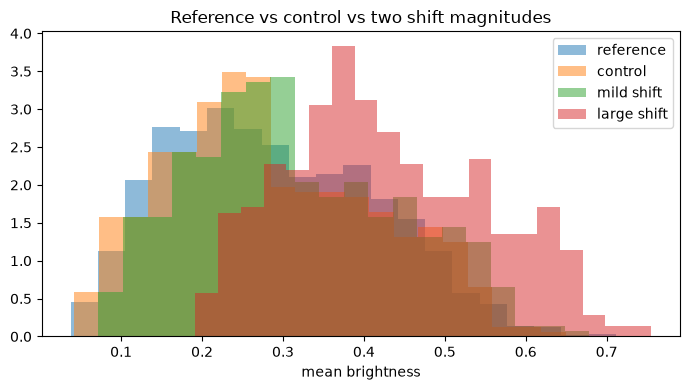

In [16]:
def histogram_counts(values, bin_edges):
    """Count fixed bins, including underflow/overflow in edge bins."""
    if values.ndim != 1:
        raise ValueError("values must be one-dimensional")
    if values.numel() == 0:
        raise ValueError("values must not be empty")
    if not torch.isfinite(values).all():
        raise ValueError("values must be finite")
    if bin_edges.ndim != 1 or bin_edges.numel() < 2:
        raise ValueError("bin_edges must contain at least two values")
    if not torch.isfinite(bin_edges).all():
        raise ValueError("bin_edges must be finite")
    if not torch.all(bin_edges[1:] > bin_edges[:-1]):
        raise ValueError("bin_edges must be strictly increasing")
    if values.device != bin_edges.device:
        raise ValueError("values and bin_edges must be on the same device")

    bin_ids = torch.bucketize(values, bin_edges[1:-1], right=True)
    return torch.bincount(bin_ids, minlength=bin_edges.numel() - 1).to(torch.float32)


# reference brightness distribution (test set)
brightness_ref = X_test.mean(dim=(1, 2, 3))
bin_edges = torch.linspace(brightness_ref.min() - 0.02, brightness_ref.max() + 0.02, 11)

# control stream: fresh, independent sample from the SAME distribution
control_X = torch.stack([test_full[i][0] for i in range(N_TEST, N_TEST + 500)])
control_y = torch.tensor([test_full[i][1] for i in range(N_TEST, N_TEST + 500)])
brightness_control = control_X.mean(dim=(1, 2, 3))

# two shifted streams: a MILD and a LARGER brightness change (simulates e.g.
# exposure/sensor change of different severity) -- shown together, not
# cherry-picked, to see the actual dose-response relationship
SHIFT_MILD = 0.03
SHIFT_LARGE = 0.15
shifted_mild_X = (control_X + SHIFT_MILD).clamp(0, 1)
shifted_large_X = (control_X + SHIFT_LARGE).clamp(0, 1)

ref_counts = histogram_counts(brightness_ref, bin_edges)
control_counts = histogram_counts(brightness_control, bin_edges)
psi_control = psi(ref_counts, control_counts)
psi_mild = psi(ref_counts, histogram_counts(shifted_mild_X.mean(dim=(1, 2, 3)), bin_edges))
psi_large = psi(ref_counts, histogram_counts(shifted_large_X.mean(dim=(1, 2, 3)), bin_edges))
print(f"PSI (ref vs control, same distribution): {psi_control:.4f}")
print(f"PSI (ref vs mild shift +{SHIFT_MILD}): {psi_mild:.4f}")
print(f"PSI (ref vs large shift +{SHIFT_LARGE}): {psi_large:.4f}")

brightness_control_plot = control_X.mean(dim=(1, 2, 3)).numpy()
brightness_mild_plot = shifted_mild_X.mean(dim=(1, 2, 3)).numpy()
brightness_large_plot = shifted_large_X.mean(dim=(1, 2, 3)).numpy()

plt.figure(figsize=(7, 4))
plt.hist(brightness_ref.numpy(), bins=20, alpha=0.5, label="reference", density=True)
plt.hist(brightness_control_plot, bins=20, alpha=0.5, label="control", density=True)
plt.hist(brightness_mild_plot, bins=20, alpha=0.5, label="mild shift", density=True)
plt.hist(brightness_large_plot, bins=20, alpha=0.5, label="large shift", density=True)
plt.xlabel("mean brightness")
plt.legend()
plt.title("Reference vs control vs two shift magnitudes")
plt.tight_layout()
plt.show()

In [17]:
model.eval()
with torch.no_grad():
    pred_control = model(control_X).argmax(1)
    pred_mild = model(shifted_mild_X).argmax(1)
    pred_large = model(shifted_large_X).argmax(1)
acc_control = (pred_control == control_y).float().mean().item()
acc_mild = (pred_mild == control_y).float().mean().item()
acc_large = (pred_large == control_y).float().mean().item()
print(f"accuracy (control): {acc_control:.4f}")
print(f"accuracy (mild shift, SAME true labels): {acc_mild:.4f}")
print(f"accuracy (large shift, SAME true labels): {acc_large:.4f}")

conf_control = F.softmax(model(control_X), dim=1).max(dim=1).values.mean().item()
conf_mild = F.softmax(model(shifted_mild_X), dim=1).max(dim=1).values.mean().item()
conf_large = F.softmax(model(shifted_large_X), dim=1).max(dim=1).values.mean().item()
print(
    f"mean confidence (control): {conf_control:.4f}, (mild): {conf_mild:.4f}, "
    f"(large): {conf_large:.4f}"
)

accuracy (control): 0.8700
accuracy (mild shift, SAME true labels): 0.8700
accuracy (large shift, SAME true labels): 0.7800


mean confidence (control): 0.8598, (mild): 0.8436, (large): 0.7573


## E. Operational decision

In [18]:
print("Summary of Experiment D:")
print(
    f"  control:     PSI={psi_control:.4f}, accuracy={acc_control:.4f} "
    f"-> no significant change, as expected (no false alarm)"
)
print(
    f"  mild shift:  PSI={psi_mild:.4f}, accuracy={acc_mild:.4f} "
    f"-> drift detected, accuracy UNCHANGED"
)
print(
    f"  large shift: PSI={psi_large:.4f}, accuracy={acc_large:.4f} "
    f"-> drift more strongly detected, accuracy NOTICEABLY dropped"
)
print()
print(
    "Operational recommendation: the RELATIONSHIP between input drift strength "
    "and the accuracy drop is NOT fixed in advance -- in this experiment, a "
    "moderate drift (mild shift) did not affect quality, but a stronger drift "
    "(large shift) did. This CONFIRMS the principle: 'detecting drift by itself "
    "does not say WHETHER and BY HOW MUCH quality dropped' -- this has to be "
    "measured SEPARATELY, not inferred from the strength of the PSI signal "
    "alone. Recommendation: (1) for a mild-shift-like alarm, continue "
    "monitoring, don't raise an alarm; (2) for a large-shift-like alarm, treat "
    "it as a signal for additional analysis/collecting labels, NOT automatic "
    "retraining without verification; (3) NEVER deploy a model change based "
    "solely on PSI, without an independent quality assessment."
)

Summary of Experiment D:
  control:     PSI=0.0225, accuracy=0.8700 -> no significant change, as expected (no false alarm)
  mild shift:  PSI=0.1317, accuracy=0.8700 -> drift detected, accuracy UNCHANGED
  large shift: PSI=2.1316, accuracy=0.7800 -> drift more strongly detected, accuracy NOTICEABLY dropped

Operational recommendation: the RELATIONSHIP between input drift strength and the accuracy drop is NOT fixed in advance -- in this experiment, a moderate drift (mild shift) did not affect quality, but a stronger drift (large shift) did. This CONFIRMS the principle: 'detecting drift by itself does not say WHETHER and BY HOW MUCH quality dropped' -- this has to be measured SEPARATELY, not inferred from the strength of the PSI signal alone. Recommendation: (1) for a mild-shift-like alarm, continue monitoring, don't raise an alarm; (2) for a large-shift-like alarm, treat it as a signal for additional analysis/collecting labels, NOT automatic retraining without verification; (3) NEVER de

In [19]:
print(f"\ntotal notebook execution time: {time.time() - notebook_t0:.1f}s")


total notebook execution time: 12.8s
